# CartPole IDK familiarity baselines

## Description

Can simple distance (kNN) or density (GMM) methods detect departure as well as IDK?
This notebook compares them using the same data and evaluation protocol as the
[randomized-start IDK experiment](idk-familiarity-action-delay-randinit.ipynb).

- Compare 4D state and 8D transition representations.
- Use randomized initial conditions:
  - $x \in [-2.2, 2.2]$
  - $\dot{x} \in [-1.0, 1.0]$
  - $\theta \in [-0.14, 0.14]$
  - $\dot{\theta} \in [-0.1, 0.1]$

## Methods

### Shared setup

- Fit kNN and GMM on successful nominal experience; reuse the saved IDK results.
- Use the saved IDK scaling for both baselines.
- Score windows of 25 and 50 transitions, moving forward 5 steps at a time.
- Set alarm thresholds using separate nominal calibration episodes, with a 10% false-alarm target.
- Require three consecutive windows above threshold to raise an alarm.
- Evaluate on held-out nominal episodes and delay-1, delay-2, and delay-3 episodes.

### Evaluation criteria

- **AUROC:** how well scores separate nominal and delayed episodes after onset.
- **Detection:** how often the first alarm occurs after onset and before the episode ends.
- **False alarms:** how often nominal test episodes trigger an alarm.
- **Latency:** how many steps detection takes after onset, among timely detections.

### IDK comparison

- $\psi$ (samples per partition): 64.
- $t$ (number of partitions): 200.
- Compare outside mass and IDK familiarity from the saved run.
- **AUROC and alarms:** evaluate separation using outside mass and negated familiarity separately. Each score triggers an alarm when three consecutive windows exceed its own threshold, calibrated on nominal episodes with a 10% false-alarm target.

### kNN

- Use up to 100,000 reference rows from successful nominal fit episodes.
- Score each 25- or 50-step row by its mean distance to the 10 nearest reference rows.
  - Euclidean (L2) distance between query & reference window $d(z,r) = \sqrt(\sum{j=1}^{D} (z_{j} - r_{j})^2)$
- Average row scores within each window; larger distances mean more anomalous behavior.
- **AUROC and alarms:** evaluate separation using the window-average neighbor distance. Alarm when three consecutive window scores exceed the kNN threshold, calibrated on nominal episodes with a 10% false-alarm target.

### Gaussian mixture likelihood

- Fit a Gaussian mixture model (GMM) to successful nominal experience.
- Try 1, 2, 4, 8, and 16 components; select using held-out nominal fit episodes.
- Refit the selected model on the same reference rows as kNN.
- Average negative log-likelihood within each window; less likely behavior gets a higher anomaly score.
- **AUROC and alarms:** evaluate separation using the window-average negative log-likelihood. Alarm when three consecutive window scores exceed the GMM threshold, calibrated on nominal episodes with a 10% false-alarm target.


In [1]:
from __future__ import annotations

import hashlib
import json
import platform
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from threadpoolctl import threadpool_limits

from cartpole_idk.artifacts import FitArtifact
from cartpole_idk.idk.features import build_sequence_batch
from cartpole_idk.idk.units import build_units
from cartpole_idk.storage import Trajectory

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
TAG = "randinit2181"
REPS = ("state", "transition")
WINDOWS = (25, 50)
STRIDE, PERSISTENCE, ALPHA = 5, 3, 0.10
SEED = 20261014
NEIGHBORS, REFERENCE_CAP = 10, 100_000
GMM_COMPONENTS = (1, 2, 4, 8, 16)
GMM_TRAIN_CAP, GMM_VALIDATION_CAP = 50_000, 20_000
GMM_REG, GMM_N_INIT, GMM_MAX_ITER = 1e-6, 2, 300
PSI, PARTITIONS = 64, 200
DELAYS = ("delay-1", "delay-2", "delay-3")
POPULATIONS = ("calibration", "nominal", *DELAYS)
METHODS = ("kNN", "GMM", "IDK outside mass", "IDK familiarity")
KEYS = ["representation", "window_length", "method"]
IDK_NAMES = {"outside-mass": "IDK outside mass", "idk-familiarity": "IDK familiarity"}
IDK_CACHE_OVERRIDE = None  # Optional Path to a particular compatible saved run.
OUTPUT = ROOT / "artifacts/analysis/nonidk-baselines"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Data and provenance

- **Baseline fitting:** use the first 300 transitions of 1,908 successful nominal episodes. Success means the original episode reached 500 steps.
- **IDK fitting:** the saved IDK models and scalers used 1,955 segments, including those 1,908 successes. We reuse these scalers, so the fitting populations differ slightly.
- **Calibration and testing:** all methods use the same 500 episodes in each population. Keep unsuccessful nominal episodes and delayed episodes that end before onset.
- **Checks:** verify that the datasets use the same policy checkpoint and initialization settings, that fit/calibration/test episodes do not overlap, and that input files match the saved IDK run.


In [2]:
fits = {
    rep: FitArtifact.load(
        ROOT / "artifacts/fit/familiarity" / f"psi-{PSI}_t-{PARTITIONS}_{rep}-{TAG}"
    )
    for rep in REPS
}
for rep, fit in fits.items():
    assert (fit.config.idk.representation, fit.config.idk.scaler) == (rep, "standard")
    assert (fit.config.idk.psi, fit.config.idk.t) == (PSI, PARTITIONS)
assert fits["state"].config.trajectory_ids == fits["transition"].config.trajectory_ids
fit_dir = ROOT / "datasets/prepared/familiarity" / fits["state"].config.dataset.name
fit_files = [fit_dir / "trajectories" / f"{tid}.npz" for tid in fits["state"].config.trajectory_ids]
prepared = [Trajectory.load(p) for p in fit_files]
successful = [
    tr for tr in prepared if tr.metadata["success"] and tr.metadata["source_length"] >= 500
]
assert all(tr.length == 300 and tr.metadata["perturbation_type"] == "none" for tr in successful)
assert len({tr.metadata["source_trajectory_id"] for tr in successful}) == len(successful)

names = {"calibration": f"calibration-nominal-{TAG}-500", "nominal": f"test-nominal-{TAG}-500"}
names.update({pop: f"{pop}-{TAG}-500" for pop in DELAYS})
raw, input_files, episode_rows = {}, list(fit_files), []
for pop, name in names.items():
    files = sorted((ROOT / "datasets/generated/familiarity" / name / "trajectories").glob("*.npz"))
    assert len(files) == 500, (pop, len(files))
    input_files.extend(files)
    raw[pop] = [Trajectory.load(p) for p in files]
    for tr in raw[pop]:
        episode_rows.append(
            dict(
                population=pop,
                episode_id=tr.trajectory_id,
                length=tr.length,
                onset=tr.metadata.get("perturbation_onset"),
                survived_500=tr.length >= 500,
            )
        )
episodes = pd.DataFrame(episode_rows)
all_trajectories = prepared + [tr for pop in POPULATIONS for tr in raw[pop]]
assert len({tr.metadata["checkpoint_path"] for tr in all_trajectories}) == 1
assert (
    len(
        {json.dumps(tr.metadata["initial_state_config"], sort_keys=True) for tr in all_trajectories}
    )
    == 1
)
source_ids = [tr.metadata.get("source_trajectory_id", tr.trajectory_id) for tr in all_trajectories]
assert len(set(source_ids)) == len(source_ids), "Fit/calibration/test populations overlap"
ANCHOR = int(round(episodes.loc[episodes.population.isin(DELAYS), "onset"].median()))

cache_root = ROOT / "artifacts/analysis/idk-familiarity-action-delay-v3"
candidates = (
    [Path(IDK_CACHE_OVERRIDE)] if IDK_CACHE_OVERRIDE else sorted(cache_root.glob("*/protocol.json"))
)
compatible = []
for candidate in candidates:
    p = candidate / "protocol.json" if candidate.is_dir() else candidate
    protocol = json.loads(p.read_text())
    if (
        protocol.get("version") == 5
        and protocol.get("query_stride") == STRIDE
        and protocol.get("alpha") == ALPHA
        and protocol.get("persistence") == PERSISTENCE
        and protocol.get("focus") == [PSI, PARTITIONS, 25]
        and all(fit.fit_id in protocol.get("fit_ids", []) for fit in fits.values())
    ):
        compatible.append((p, protocol))
if len(compatible) != 1:
    raise ValueError(
        f"Expected one compatible IDK cache, found {len(compatible)}; "
        "run the randomized-start notebook or set IDK_CACHE_OVERRIDE."
    )
protocol_path, idk_protocol = compatible[0]
IDK_CACHE = protocol_path.parent
saved_inputs = {name: (size, mtime) for name, size, mtime in idk_protocol["input_files"]}
input_inventory = []
for p in input_files:
    stat = p.stat()
    relative = str(p.relative_to(ROOT))
    assert saved_inputs.get(relative) == (stat.st_size, stat.st_mtime_ns), (
        f"Changed IDK input: {relative}"
    )
    input_inventory.append([relative, stat.st_size, stat.st_mtime_ns])
print(f"Successful fit prefixes: {len(successful)} / {len(prepared)}; nominal anchor: {ANCHOR}")
print("IDK cache:", IDK_CACHE.relative_to(ROOT))
display(
    episodes.assign(onset_reached=lambda x: x.onset.lt(x.length))
    .groupby("population")
    .agg(
        episodes=("episode_id", "size"),
        survival=("survived_500", "mean"),
        median_length=("length", "median"),
        reaching_onset=("onset_reached", "sum"),
    )
    .round(3)
)

Successful fit prefixes: 1908 / 1955; nominal anchor: 100
IDK cache: artifacts/analysis/idk-familiarity-action-delay-v3/d3b90acef455d000


,episodes,survival,median_length,reaching_onset
population,,,,
calibration,500,0.952,500.0,0
delay-1,500,0.346,389.5,479
delay-2,500,0.202,323.0,481
delay-3,500,0.092,262.5,474
nominal,500,0.952,500.0,0


## Fit only on nominal experience

**kNN:** store up to 100,000 reference rows. Score each row by its average distance
to the 10 nearest reference rows.

**GMM:** use successful nominal fit episodes to choose the model:

1. Split episodes 80/20 for training and validation, keeping each episode in one split.
2. Sample up to 50,000 training rows and 20,000 validation rows.
3. Try 1, 2, 4, 8, and 16 components. Choose the lowest validation BIC, which balances likelihood against model complexity.
4. Refit on the same reference rows as kNN.

All GMMs use full covariance; invalid or unconverged fits are rejected. BIC is evaluated
on validation data here. The saved scaler has seen both fit splits, but no calibration
or test episodes.

GMM scores are negative log-likelihood, $-\log p(x)$. Both baselines average row scores
within each window, weighting rows equally. An $L$-transition window has $L+1$ state rows
or $L$ transition rows, matching IDK.


In [3]:
def represented(trajectories, rep):
    fit = fits[rep]
    batch = build_sequence_batch(trajectories, fit.config.idk)
    values = fit.scaler.transform(batch.values)
    assert np.isfinite(values).all()
    return values


def sample_rows(values, cap, seed):
    indices = np.sort(
        np.random.default_rng(seed).choice(len(values), min(cap, len(values)), replace=False)
    )
    return values[indices]


def new_gmm(components):
    return GaussianMixture(
        n_components=components,
        covariance_type="full",
        reg_covar=GMM_REG,
        n_init=GMM_N_INIT,
        max_iter=GMM_MAX_ITER,
        random_state=SEED,
    )


order = np.random.default_rng(SEED).permutation(len(successful))
split = int(0.8 * len(order))
train_episodes = [successful[i] for i in order[:split]]
validation_episodes = [successful[i] for i in order[split:]]
models, selection_rows, fit_rows = {}, [], []
with threadpool_limits(limits=1):
    for rep in REPS:
        started = time.perf_counter()
        reference = sample_rows(represented(successful, rep), REFERENCE_CAP, SEED)
        train = sample_rows(represented(train_episodes, rep), GMM_TRAIN_CAP, SEED + 1)
        validation = sample_rows(
            represented(validation_episodes, rep), GMM_VALIDATION_CAP, SEED + 2
        )
        knn = NearestNeighbors(
            n_neighbors=NEIGHBORS, algorithm="kd_tree", metric="euclidean", n_jobs=1
        )
        knn.fit(reference)
        candidates = []
        for components in GMM_COMPONENTS:
            model = new_gmm(components)
            try:
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always", ConvergenceWarning)
                    model.fit(train)
                bic = model.bic(validation)
                valid = model.converged_ and np.isfinite(bic)
                note = "; ".join(str(w.message) for w in caught)
                iterations = model.n_iter_
            except (ValueError, np.linalg.LinAlgError) as exc:
                bic, valid, iterations, note = np.nan, False, 0, str(exc)
            selection_rows.append(
                dict(
                    representation=rep,
                    components=components,
                    validation_bic=bic,
                    converged=valid,
                    iterations=iterations,
                    note=note,
                )
            )
            if valid:
                candidates.append((bic, components))
        if not candidates:
            raise RuntimeError(
                f"No converged full-covariance GMM for {rep}; inspect selection_rows"
            )
        _, selected_k = min(candidates)
        gmm = new_gmm(selected_k).fit(reference)
        assert gmm.converged_ and np.isfinite(gmm.score_samples(validation)).all()
        models[rep] = {"kNN": knn, "GMM": gmm}
        fit_rows.append(
            dict(
                representation=rep,
                dimension=reference.shape[1],
                reference_rows=len(reference),
                train_rows=len(train),
                validation_rows=len(validation),
                selected_K=selected_k,
                covariance=gmm.covariance_type,
                refit_iterations=gmm.n_iter_,
                fit_seconds=time.perf_counter() - started,
            )
        )
        print(
            f"{rep}: K={selected_k}, full covariance, {time.perf_counter() - started:.1f}s",
            flush=True,
        )
selection = pd.DataFrame(selection_rows)
fit_summary = pd.DataFrame(fit_rows)
display(fit_summary.round(2))
display(
    selection.pivot(index="components", columns="representation", values="validation_bic").round(1)
)
if (~selection.converged).any():
    display(selection.loc[~selection.converged])

state: K=16, full covariance, 7.7s


transition: K=16, full covariance, 8.9s


,representation,dimension,reference_rows,train_rows,validation_rows,selected_K,covariance,refit_iterations,fit_seconds
0,state,4,100000,50000,20000,16,full,50,7.70
1,transition,8,100000,50000,20000,16,full,43,8.86


representation,state,transition
components,,
1,187449.9,-424268.7
2,178668.1,-437652.6
4,161021.9,-457115.4
8,143904.1,-685672.3
16,120138.7,-731274.4


## Common windows and the saved IDK reference

Score each baseline row once, then reuse those scores to average over the 25- and
50-transition windows. Check that all four methods score exactly the same windows.

Load the saved IDK outside-mass and familiarity scores for the selected settings.
Negate familiarity so that higher scores mean more anomalous behavior for every method.
IDK familiarity uses its original independent nominal reference bank; kNN and GMM use
the successful fit data described above.


In [4]:
def row_anomalies(values, model, method):
    chunks = []
    for start in range(0, len(values), 8192):
        x = values[start : start + 8192]
        score = (
            model.kneighbors(x, return_distance=True)[0].mean(axis=1)
            if method == "kNN"
            else -model.score_samples(x)
        )
        chunks.append(score)
    return np.concatenate(chunks)


def window_means(scores, starts, width):
    cumulative = np.r_[0.0, np.cumsum(scores, dtype=np.float64)]
    return (cumulative[starts + width] - cumulative[starts]) / width


baseline_tables = []
with threadpool_limits(limits=1):
    for rep in REPS:
        started = time.perf_counter()
        for pop in POPULATIONS:
            values = represented(raw[pop], rep)
            counts = [tr.length + (rep == "state") for tr in raw[pop]]
            offsets = np.r_[0, np.cumsum(counts)]
            assert offsets[-1] == len(values)
            for method, model in models[rep].items():
                row_scores = row_anomalies(values, model, method)
                assert np.isfinite(row_scores).all()
                for i, tr in enumerate(raw[pop]):
                    scores = row_scores[offsets[i] : offsets[i + 1]]
                    for length in WINDOWS:
                        starts = np.arange(0, tr.length - length + 1, STRIDE)
                        if not len(starts):
                            continue
                        width = length + (rep == "state")
                        baseline_tables.append(
                            pd.DataFrame(
                                dict(
                                    representation=rep,
                                    method=method,
                                    population=pop,
                                    episode_id=tr.trajectory_id,
                                    window_length=length,
                                    start_step=starts,
                                    end_step=starts + length,
                                    anomaly=window_means(scores, starts, width),
                                )
                            )
                        )
        print(f"Scored {rep}: {time.perf_counter() - started:.1f}s", flush=True)
baseline_scores = pd.concat(baseline_tables, ignore_index=True)
del baseline_tables

idk_tables, idk_files = [], []
for rep in REPS:
    for length in WINDOWS:
        for pop in POPULATIONS:
            p = (
                IDK_CACHE
                / f"windows_psi-{PSI}_t-{PARTITIONS}_{rep}-{TAG}_{pop}_k{length}_mean_core.parquet"
            )
            frame = pd.read_parquet(p, filters=[("metric", "in", list(IDK_NAMES))])
            frame["method"] = frame.metric.map(IDK_NAMES)
            expected = np.where(frame.metric.eq("idk-familiarity"), -frame.score, frame.score)
            np.testing.assert_allclose(frame.anomaly, expected)
            idk_tables.append(frame[baseline_scores.columns])
            idk_files.append(p)
idk_scores = pd.concat(idk_tables, ignore_index=True)
scores = pd.concat([baseline_scores, idk_scores], ignore_index=True)
del baseline_scores, idk_scores, idk_tables
assert np.isfinite(scores.anomaly).all()

# Every method must score the same complete windows, including short episodes.
identity = ["representation", "window_length", "population", "episode_id", "start_step", "end_step"]
expected = (
    scores.loc[scores.method.eq("kNN"), identity].sort_values(identity).reset_index(drop=True)
)
for method in METHODS[1:]:
    actual = (
        scores.loc[scores.method.eq(method), identity].sort_values(identity).reset_index(drop=True)
    )
    pd.testing.assert_frame_equal(actual, expected)

# Check cached row slicing against independently constructed repository windows.
for rep in REPS:
    tr = raw["nominal"][0]
    full = represented([tr], rep)
    for length in WINDOWS:
        unit = build_units([tr], mode="window", window_length=length, stride=STRIDE).units[1]
        np.testing.assert_allclose(
            represented([unit.trajectory], rep), full[STRIDE : STRIDE + length + (rep == "state")]
        )
print(f"{len(scores):,} scored windows; identical identities across all four methods.")

Scored state: 5.2s


Scored transition: 6.1s


2,782,952 scored windows; identical identities across all four methods.


## Evaluation protocol

**AUROC:** use one window per episode: the first complete window starting at or after
onset for delayed episodes, or at or after step 100 for nominal episodes. This matches
the earlier notebook. Episodes that end too soon are excluded; counts and coverage
show how many contribute.

**Alarm thresholds:** calibrate each method, representation, and window length separately
using nominal episodes only. Require three consecutive scores strictly above threshold.
The threshold uses each calibration episode's strongest sustained score, with a 10%
episode-level false-alarm target. The actual test rate can differ.

The code computes sustained scores as the minimum of three consecutive window scores,
then takes the maximum per episode. Calibration episodes with no complete window are
omitted; those with fewer than three windows contribute negative infinity.

**Counting alarms:**

- Monitor from episode start; windows may overlap onset.
- Only the first alarm counts. A timely detection must occur strictly after onset and before the episode ends.
- Alarms at or before onset are reported separately. A later alarm cannot rescue an early one; an alarm at termination is too late.
- Detection and nominal false-alarm rates include all 500 episodes per population, even those too short to alarm.
- Latency includes timely detections only. Read it alongside detection rate: a fast detector may still miss most episodes.


In [5]:
def sustained_trace(frame):
    ordered = frame.sort_values("end_step")
    if len(ordered) > 1:
        assert np.all(np.diff(ordered.end_step) == STRIDE), (
            "Missing/duplicated window in alarm trace"
        )
    trace = ordered.anomaly.rolling(PERSISTENCE, min_periods=PERSISTENCE).min()
    return ordered, trace


def calibration_threshold(frame):
    maxima = []
    for _, group in frame.groupby("episode_id"):
        _, trace = sustained_trace(group)
        maxima.append(trace.max() if trace.notna().any() else -np.inf)
    rank = int(np.ceil((len(maxima) + 1) * (1 - ALPHA)))
    threshold = float(np.sort(maxima)[rank - 1]) if 0 < rank <= len(maxima) else np.inf
    return (
        threshold,
        len(maxima),
        float(np.mean(np.asarray(maxima) > threshold)) if maxima else np.nan,
    )


def first_window(frame, population):
    group = frame[frame.population.eq(population)].merge(
        episodes.loc[episodes.population.eq(population), ["episode_id", "onset"]],
        on="episode_id",
        validate="many_to_one",
    )
    onset = ANCHOR if population == "nominal" else group.onset
    return (
        group[group.start_step >= onset]
        .sort_values("end_step")
        .groupby("episode_id", as_index=False)
        .head(1)
    )


def alarm_decision(first_alarm, onset, length):
    pre_onset = bool(np.isfinite(first_alarm) and first_alarm <= onset)
    timely = bool(np.isfinite(first_alarm) and onset < first_alarm < length)
    return pre_onset, timely, first_alarm - onset if timely else np.nan


def evaluate(all_scores):
    alarm_rows, auc_rows, calibration_rows = [], [], []
    for key, group in all_scores.groupby(KEYS, sort=False):
        identity = dict(zip(KEYS, key, strict=True))
        threshold, n_cal, cal_fpr = calibration_threshold(group[group.population.eq("calibration")])
        calibration_rows.append(
            dict(
                **identity,
                threshold=threshold,
                scored_calibration_episodes=n_cal,
                calibration_fpr_scored=cal_fpr,
            )
        )
        nominal_first = first_window(group, "nominal")
        for pop in DELAYS:
            delayed_first = first_window(group, pop)
            labels = np.r_[np.zeros(len(nominal_first)), np.ones(len(delayed_first))]
            anomaly = np.r_[nominal_first.anomaly, delayed_first.anomaly]
            auc = (
                roc_auc_score(labels, anomaly)
                if len(nominal_first) and len(delayed_first)
                else np.nan
            )
            auc_rows.append(
                dict(
                    **identity,
                    delay_population=pop,
                    auroc=auc,
                    n_nominal_auc=len(nominal_first),
                    n_delay_auc=len(delayed_first),
                    delay_coverage=len(delayed_first) / episodes.population.eq(pop).sum(),
                )
            )
        by_episode = dict(tuple(group.groupby(["population", "episode_id"])))
        for episode in episodes.loc[~episodes.population.eq("calibration")].itertuples(index=False):
            frame = by_episode.get((episode.population, episode.episode_id), group.iloc[:0])
            ordered, trace = sustained_trace(frame)
            endpoints = ordered.loc[trace > threshold, "end_step"]
            first_alarm = float(endpoints.iloc[0]) if len(endpoints) else np.nan
            pre, timely, latency = alarm_decision(first_alarm, episode.onset, episode.length)
            alarm_rows.append(
                dict(
                    **identity,
                    population=episode.population,
                    episode_id=episode.episode_id,
                    first_alarm=first_alarm,
                    alarm=np.isfinite(first_alarm),
                    pre_onset_alarm=pre,
                    timely_detection=timely,
                    latency=latency,
                    can_alarm=bool(trace.notna().any()),
                )
            )
    alarms = pd.DataFrame(alarm_rows)
    summary_rows = []
    for key, group in alarms.groupby(KEYS, sort=False):
        nominal = group[group.population.eq("nominal")]
        for pop in DELAYS:
            delayed = group[group.population.eq(pop)]
            summary_rows.append(
                dict(
                    **dict(zip(KEYS, key, strict=True)),
                    delay_population=pop,
                    nominal_fpr=nominal.alarm.mean(),
                    timely_detection_rate=delayed.timely_detection.mean(),
                    pre_onset_alarm_rate=delayed.pre_onset_alarm.mean(),
                    unscorable_fraction=1 - delayed.can_alarm.mean(),
                    median_latency=delayed.latency.median(),
                    n_nominal=len(nominal),
                    n_delay=len(delayed),
                )
            )
    summary = pd.DataFrame(summary_rows).merge(
        pd.DataFrame(auc_rows), on=KEYS + ["delay_population"], validate="one_to_one"
    )
    return alarms, summary, pd.DataFrame(calibration_rows)


# Boundary checks: strict ties, incomplete persistence, pre-onset and terminal alarms.
fixture = pd.DataFrame(
    {"episode_id": ["a"] * 3, "end_step": [25, 30, 35], "anomaly": [1.0, 1.0, 1.0]}
)
assert not (sustained_trace(fixture)[1] > 1.0).any()
assert sustained_trace(fixture.iloc[:2])[1].isna().all()
assert calibration_threshold(fixture.iloc[:0])[0] == np.inf
assert alarm_decision(100, 100, 500)[:2] == (True, False)
assert alarm_decision(120, 100, 120)[:2] == (False, False)
assert alarm_decision(115, 100, 120) == (False, True, 15)
np.testing.assert_allclose(
    window_means(np.array([1.0, 3.0, 5.0, 7.0]), np.array([0, 1]), 3), [3.0, 5.0]
)
alarms, results, calibration = evaluate(scores)

In [6]:
# Recomputed IDK metrics must reproduce the original saved numerical tables.
comparison_keys = ["representation", "window_length", "method", "delay_population"]
for filename, metrics in [
    (
        "alarm_summary.csv",
        [
            "nominal_fpr",
            "timely_detection_rate",
            "median_latency",
            "pre_onset_alarm_rate",
            "unscorable_fraction",
        ],
    ),
    ("post_onset_sample_efficiency.csv", ["auroc", "delay_coverage"]),
]:
    saved = pd.read_csv(IDK_CACHE / filename)
    saved = saved.query(
        "psi == @PSI and t == @PARTITIONS and representation in @REPS and window_length in @WINDOWS"
    ).copy()
    saved["method"] = saved.metric.map(IDK_NAMES)
    saved = saved[saved.method.notna()]
    current = results[results.method.isin(IDK_NAMES.values())]
    matched = current.merge(
        saved, on=comparison_keys, suffixes=("_new", "_saved"), validate="one_to_one"
    )
    assert len(matched) == len(current) == 24
    for metric in metrics:
        np.testing.assert_allclose(
            matched[metric + "_new"],
            matched[metric + "_saved"],
            atol=1e-12,
            rtol=1e-12,
            equal_nan=True,
        )
print(
    "Protocol check passed: IDK AUROC, coverage, FPR, detection, pre-onset alarms, "
    "and latency match saved results."
)

display(calibration.drop(columns="threshold").round(3))
display(
    results[
        [
            "representation",
            "window_length",
            "method",
            "delay_population",
            "auroc",
            "timely_detection_rate",
            "nominal_fpr",
            "median_latency",
        ]
    ]
    .sort_values(comparison_keys)
    .round(3)
)
display(
    results[results.method.eq("kNN")][
        [
            "representation",
            "window_length",
            "delay_population",
            "n_nominal_auc",
            "n_delay_auc",
            "delay_coverage",
            "unscorable_fraction",
        ]
    ].round(3)
)

Protocol check passed: IDK AUROC, coverage, FPR, detection, pre-onset alarms, and latency match saved results.


,representation,window_length,method,scored_calibration_episodes,calibration_fpr_scored
0,state,25,kNN,488,0.096
1,state,50,kNN,483,0.097
2,state,25,GMM,488,0.096
3,state,50,GMM,483,0.097
4,transition,25,kNN,488,0.096
5,transition,50,kNN,483,0.097
6,transition,25,GMM,488,0.096
7,transition,50,GMM,483,0.097
8,state,25,IDK familiarity,488,0.096
9,state,25,IDK outside mass,488,0.096


,representation,window_length,method,delay_population,auroc,timely_detection_rate,nominal_fpr,median_latency
6,state,25,GMM,delay-1,0.915,0.286,0.084,157.0
7,state,25,GMM,delay-2,0.995,0.860,0.084,35.0
8,state,25,GMM,delay-3,0.999,0.822,0.084,25.0
24,state,25,IDK familiarity,delay-1,0.631,0.008,0.104,171.0
25,state,25,IDK familiarity,delay-2,0.850,0.186,0.104,51.0
26,state,25,IDK familiarity,delay-3,0.974,0.568,0.104,41.0
27,state,25,IDK outside mass,delay-1,0.941,0.022,0.088,171.0
28,state,25,IDK outside mass,delay-2,0.984,0.772,0.088,58.0
29,state,25,IDK outside mass,delay-3,0.997,0.796,0.088,32.0
0,state,25,kNN,delay-1,0.993,0.752,0.084,56.0


,representation,window_length,delay_population,n_nominal_auc,n_delay_auc,delay_coverage,unscorable_fraction
0,state,25,delay-1,476,469,0.938,0.036
1,state,25,delay-2,476,456,0.912,0.026
2,state,25,delay-3,476,439,0.878,0.036
3,state,50,delay-1,476,464,0.928,0.040
4,state,50,delay-2,476,442,0.884,0.036
5,state,50,delay-3,476,402,0.804,0.040
12,transition,25,delay-1,476,469,0.938,0.036
13,transition,25,delay-2,476,456,0.912,0.026
14,transition,25,delay-3,476,439,0.878,0.036
15,transition,50,delay-1,476,464,0.928,0.040


## Detection, false alarms, and timing

Each row of plots uses one representation and window length. Colors identify methods;
the horizontal axis shows delay severity. The columns show AUROC, timely detection rate,
and median latency.

Read latency together with detection rate: a method can look fast if it detects only a
few episodes. Nominal false-alarm rates are in the table above.

The table below the plots shows the change from state to transition for mild delay.
Higher AUROC and detection are better; lower false-alarm rates and latency are better.


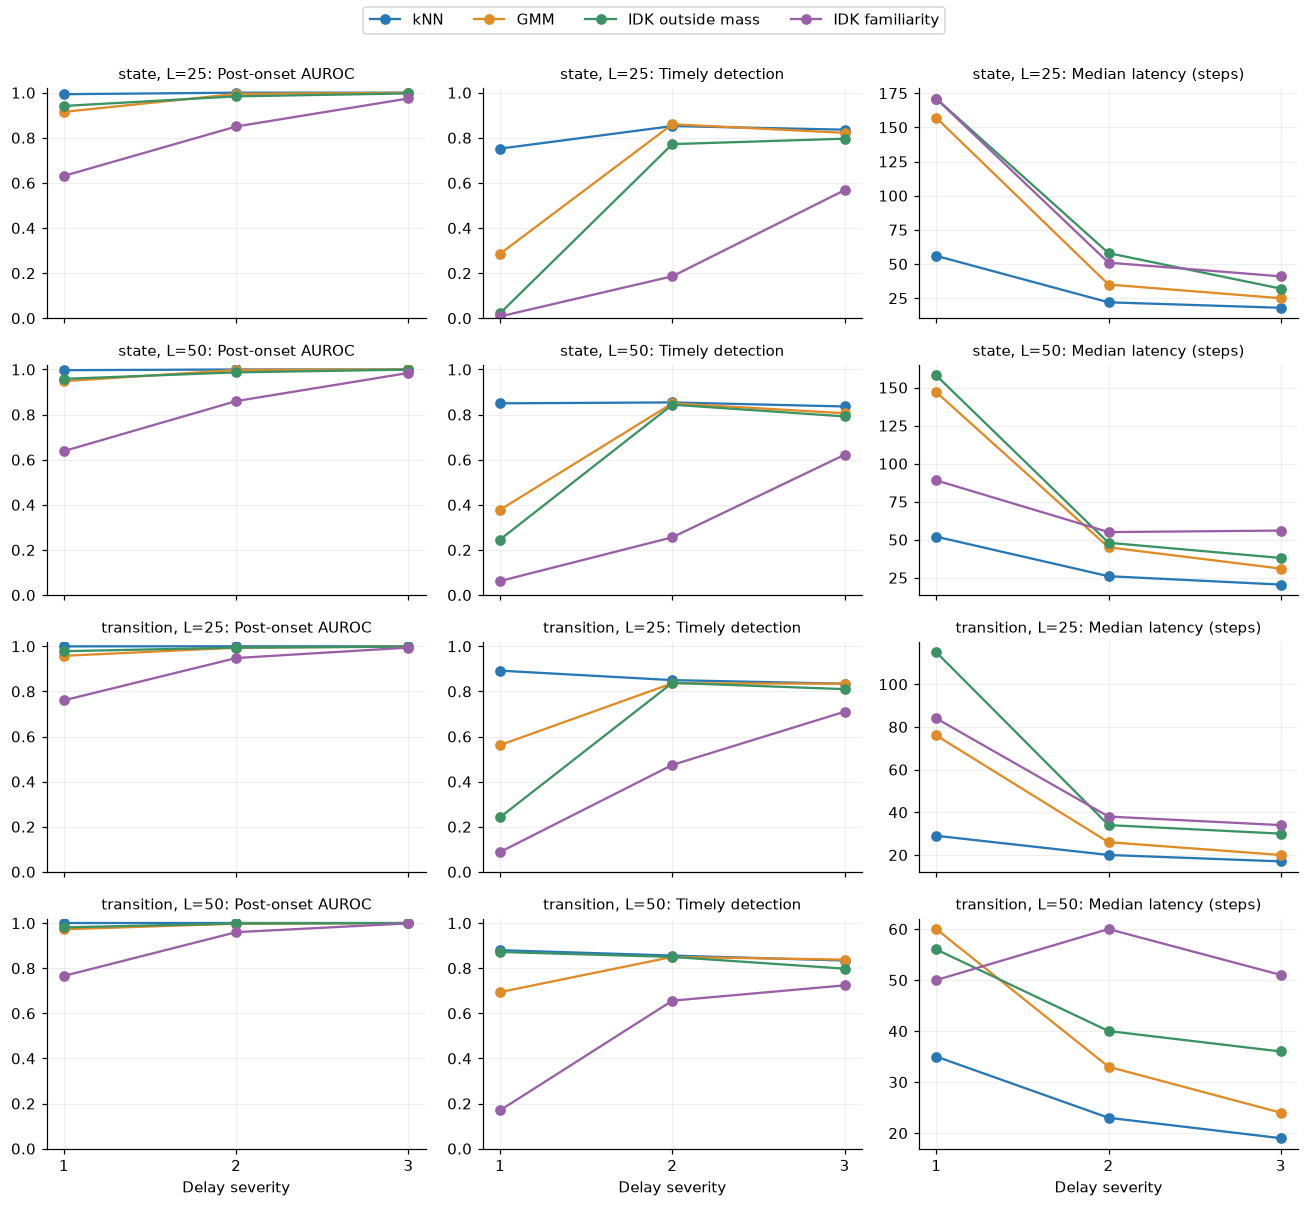

**Transition minus state, delay-1:**

auroc  timely_detection_rate  nominal_fpr  \
window_length method                                                        
25            kNN               0.006                  0.140        0.006   
50            kNN               0.003                  0.030        0.004   
25            GMM               0.043                  0.276        0.002   
50            GMM               0.024                  0.316        0.018   
25            IDK familiarity   0.129                  0.080       -0.006   
              IDK outside mass  0.037                  0.220       -0.006   
50            IDK familiarity   0.127                  0.108        0.002   
              IDK outside mass  0.023                  0.626       -0.004   

                                median_latency  
window_length method                            
25            kNN                        -27.0  
50            kNN                        -17.0  
25            GMM                        -81.0  
50            GMM                        -87.0  
25            IDK familiarity            -87.0  
              IDK outside mass           -56.0  
50            IDK familiarity            -39.0  
              IDK outside mass          -102.0

In [7]:
colors = dict(zip(METHODS, ["#2878b5", "#e08b26", "#3b9363", "#9a60a7"], strict=True))
fig, axes = plt.subplots(4, 3, figsize=(12, 11), sharex=True)
for row, (rep, length) in enumerate((r, length) for r in REPS for length in WINDOWS):
    for method in METHODS:
        group = results.query(
            "representation == @rep and window_length == @length and method == @method"
        ).sort_values("delay_population")
        for col, (metric, label) in enumerate(
            [
                ("auroc", "Post-onset AUROC"),
                ("timely_detection_rate", "Timely detection"),
                ("median_latency", "Median latency (steps)"),
            ]
        ):
            axes[row, col].plot([1, 2, 3], group[metric], "o-", color=colors[method], label=method)
            axes[row, col].set_title(f"{rep}, L={length}: {label}", fontsize=10)
            axes[row, col].grid(alpha=0.2)
            if col < 2:
                axes[row, col].set_ylim(0, 1.02)
            axes[row, col].set_xticks([1, 2, 3])
for ax in axes[-1]:
    ax.set_xlabel("Delay severity")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(OUTPUT / "comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Mild-delay representation changes: positive AUROC/detection and negative FPR/latency help.
mild = results.query("delay_population == 'delay-1'")
delta_metrics = ["auroc", "timely_detection_rate", "nominal_fpr", "median_latency"]
state = mild.query("representation == 'state'").set_index(["window_length", "method"])[
    delta_metrics
]
transition = mild.query("representation == 'transition'").set_index(["window_length", "method"])[
    delta_metrics
]
representation_delta = transition - state
display(Markdown("**Transition minus state, delay-1:**"))
display(representation_delta.round(3))

## Answers from this run

The results below use one checkpoint, one nominal-data split, and the fixed settings
listed above. Small differences need confirmation on new runs.

AUROC uses one fully post-onset window per eligible episode. Online detection monitors
the whole episode. The disagreement table counts episodes detected by IDK but missed by
both baselines, and vice versa.


In [8]:
# Compact measured evidence for the seven questions, also exported for inspection.
def measured_line(rep, length, pop):
    group = results.query(
        "representation == @rep and window_length == @length and delay_population == @pop"
    )
    entries = []
    for method in METHODS:
        r = group[group.method.eq(method)].iloc[0]
        entries.append(
            f"{method}: AUC {r.auroc:.3f}, detect {r.timely_detection_rate:.1%}, "
            f"FPR {r.nominal_fpr:.1%}, latency {r.median_latency:g}"
        )
    return f"**{rep}, L={length}, {pop}:** " + "; ".join(entries) + "."


evidence = "\n\n".join(measured_line(rep, length, "delay-1") for rep in REPS for length in WINDOWS)
display(Markdown(evidence))

# Paired episode counts: do IDK alarms rescue cases missed by both baselines?
paired = alarms[alarms.population.isin(DELAYS)].pivot(
    index=["representation", "window_length", "population", "episode_id"],
    columns="method",
    values="timely_detection",
)
baseline_detected = paired["kNN"] | paired["GMM"]
disagreements = (
    pd.DataFrame(
        {
            "outside_mass_only": paired["IDK outside mass"] & ~baseline_detected,
            "familiarity_only": paired["IDK familiarity"] & ~baseline_detected,
            "baseline_only": baseline_detected
            & ~paired["IDK outside mass"]
            & ~paired["IDK familiarity"],
        }
    )
    .groupby(level=[0, 1, 2])
    .sum()
)
display(
    Markdown(
        "**Timely detections per 500 episodes:** IDK columns count cases missed by "
        "both baselines; baseline-only counts cases missed by both IDK scores. "
        "These are descriptive disagreements, not a calibrated ensemble."
    )
)
display(disagreements)

**state, L=25, delay-1:** kNN: AUC 0.993, detect 75.2%, FPR 8.4%, latency 56; GMM: AUC 0.915, detect 28.6%, FPR 8.4%, latency 157; IDK outside mass: AUC 0.941, detect 2.2%, FPR 8.8%, latency 171; IDK familiarity: AUC 0.631, detect 0.8%, FPR 10.4%, latency 171.

**state, L=50, delay-1:** kNN: AUC 0.997, detect 85.0%, FPR 5.4%, latency 52; GMM: AUC 0.948, detect 37.8%, FPR 8.4%, latency 147; IDK outside mass: AUC 0.958, detect 24.6%, FPR 6.4%, latency 158; IDK familiarity: AUC 0.638, detect 6.2%, FPR 8.0%, latency 89.

**transition, L=25, delay-1:** kNN: AUC 1.000, detect 89.2%, FPR 9.0%, latency 29; GMM: AUC 0.958, detect 56.2%, FPR 8.6%, latency 76; IDK outside mass: AUC 0.978, detect 24.2%, FPR 8.2%, latency 115; IDK familiarity: AUC 0.760, detect 8.8%, FPR 9.8%, latency 84.

**transition, L=50, delay-1:** kNN: AUC 1.000, detect 88.0%, FPR 5.8%, latency 35; GMM: AUC 0.973, detect 69.4%, FPR 10.2%, latency 60; IDK outside mass: AUC 0.981, detect 87.2%, FPR 6.0%, latency 56; IDK familiarity: AUC 0.766, detect 17.0%, FPR 8.2%, latency 50.

**Timely detections per 500 episodes:** IDK columns count cases missed by both baselines; baseline-only counts cases missed by both IDK scores. These are descriptive disagreements, not a calibrated ensemble.

outside_mass_only  familiarity_only  \
representation window_length population                                        
state          25            delay-1                     0                 0   
                             delay-2                     3                 0   
                             delay-3                     2                 2   
               50            delay-1                     0                 8   
                             delay-2                     4                 4   
                             delay-3                     3                11   
transition     25            delay-1                     1                 0   
                             delay-2                     4                 3   
                             delay-3                     0                 3   
               50            delay-1                     5                 6   
                             delay-2                     1                 6   
                             delay-3                     2                10   

                                         baseline_only  
representation window_length population                 
state          25            delay-1               367  
                             delay-2                60  
                             delay-3                35  
               50            delay-1               289  
                             delay-2                21  
                             delay-3                29  
transition     25            delay-1               291  
                             delay-2                21  
                             delay-3                24  
               50            delay-1                15  
                             delay-2                11  
                             delay-3                21

## Comparison Results

1. **kNN detects mild delay at least as well as IDK outside-mass.  IDK familiarity performs worst.** The difference between kNN and IDK outside-mass is greatest for delay 1 episodes, though at 50 steps detection starts looking similar. kNN is faster to detect alarms.  GMM performs on par with outside-mass for departure detection, but is also faster to detect alarms.

2. **GMM's performance depends on the setting.** It detects more mild delays than idk-familiarity throughout, and more than outside mass except with 50-step transition windows. Both representations selected 16 components, the largest number tried.

3. **Transitions help both baselines.** For mild delay with 25-step windows, switching from state to transition raises kNN detection from 75.2% to 89.2% and GMM from 28.6% to 56.2%. Both also improve at 50 steps, and AUROC and latency improve. This benefit is shared with IDK.

4. **The results support the support/OOD interpretation of outside mass.** Simple distance detects departure at least as well here, with faster median alarms. Strong state-only kNN results show that departure is already visible in individual states. This does not establish that the scores contain identical information.

5. **Declining alarm rates for kNN / outside-mass.**  You brought this up as a possible issue.  I *think* it is likely due to the fact that as the severity increases, the average number of steps after delay drops, leaving less time for the alarm to trigger before episode termination.

**Limits of the comparison**

- These are results from one run; no significance tests were performed.
- AUROC excludes early endings. Depending on severity, delayed-episode coverage is 87.8–93.8% at 25 steps and 80.4–92.8% at 50 steps. There are 476 eligible nominal episodes. Online rates include all 500.
- Actual false-alarm rates range from 5.4% to 10.4%, so small detection differences are not comparisons at equal false-alarm rates.
- The baselines use 100,000 successful fit rows. IDK keeps its saved model and independent reference bank. Memory and compute budgets are not matched.


In [9]:
# Persist numerical results, sampled episode IDs, settings, and input/cache fingerprints.
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


provenance = dict(
    version=1,
    dataset_tag=TAG,
    representations=REPS,
    windows=WINDOWS,
    stride=STRIDE,
    persistence=PERSISTENCE,
    alpha=ALPHA,
    random_state=SEED,
    neighbors=NEIGHBORS,
    reference_cap=REFERENCE_CAP,
    gmm_components=GMM_COMPONENTS,
    gmm_train_cap=GMM_TRAIN_CAP,
    gmm_validation_cap=GMM_VALIDATION_CAP,
    gmm_reg_covar=GMM_REG,
    gmm_covariance="full",
    gmm_n_init=GMM_N_INIT,
    gmm_max_iter=GMM_MAX_ITER,
    fit_ids={rep: fit.fit_id for rep, fit in fits.items()},
    gmm_training_episodes=[tr.trajectory_id for tr in train_episodes],
    gmm_validation_episodes=[tr.trajectory_id for tr in validation_episodes],
    idk_cache=str(IDK_CACHE.relative_to(ROOT)),
    idk_protocol_sha256=sha256(protocol_path),
    idk_window_sha256={p.name: sha256(p) for p in idk_files},
    input_inventory=input_inventory,
    software=dict(
        python=platform.python_version(),
        numpy=np.__version__,
        pandas=pd.__version__,
        sklearn=sklearn.__version__,
    ),
)
for name, frame in {
    "results": results,
    "calibration": calibration,
    "gmm_selection": selection,
    "fit_summary": fit_summary,
}.items():
    frame.to_csv(OUTPUT / f"{name}.csv", index=False)
disagreements.to_csv(OUTPUT / "paired_detection_disagreements.csv")
representation_delta.to_csv(OUTPUT / "mild_delay_representation_delta.csv")
alarms.to_parquet(OUTPUT / "alarm_episodes.parquet", index=False)
scores.to_parquet(OUTPUT / "window_scores.parquet", index=False)
(OUTPUT / "protocol.json").write_text(json.dumps(provenance, indent=2))
(OUTPUT / "measured_evidence.md").write_text(evidence)
print("Saved tables, scores, figure, and provenance:", OUTPUT.relative_to(ROOT))

Saved tables, scores, figure, and provenance: artifacts/analysis/nonidk-baselines
